# updated version of RD900 analysis to detect region differences using raw reads

links

* https://journals.plos.org/plospathogens/article?id=10.1371/journal.ppat.1009061
* https://dmnfarrell.github.io/bioinformatics/rd900-mtbc

In [67]:
import sys, os, io, csv, glob, subprocess, time, re
import posixpath, urllib, gzip, shutil
from importlib import reload
from pathlib import Path
from collections import defaultdict
import pandas as pd
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqFeature import SeqFeature, FeatureLocation
from Bio import Entrez
from BCBio import GFF
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import pylab as plt
import seaborn as sns
import networkx as nx
from snipgenie import tools, aligners, app, trees, plotting
import locustools as lt

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)

In [2]:
Entrez.email = "you@example.com"
Entrez.api_key = "8bffceb973ebf5e6d371cc55a8244ae66a09"

In [14]:
species = [ 
        #'Mycobacterium tuberculosis',
        #'Mycobacterium tuberculosis variant bovis',
        'Mycobacterium tuberculosis variant africanum' ,
        'Mycobacterium tuberculosis variant caprae',
        'Mycobacterium orygis',
        'Mycobacterium tuberculosis variant microti',
        'Mycobacterium tuberculosis variant pinnipedii', 
        'Mycobacterium tuberculosis variant suricattae'
    ]  

## complete genomes for MTB species

In [3]:
def build_query(species: List[str]) -> str:
    """Build an Entrez query: (species OR species OR ...) AND Complete Genome."""
    
    species_clause = " OR ".join(f'"{sp}"[Organism]' for sp in species)
    query = f'({species_clause})'
    return query

def esearch_all_ids(query: str, db: str = "assembly", batch_size: int = 500) -> List[str]:
    """Run esearch with history, return all UIDs (handles >retmax results)."""
    handle = Entrez.esearch(db=db, term=query, usehistory="y", retmax=0)
    result = Entrez.read(handle)
    handle.close()
 
    count = int(result["Count"])
    webenv = result["WebEnv"]
    query_key = result["QueryKey"]
 
    print(f"Query: {query}")
    print(f"Total matching assemblies: {count}")
 
    ids: List[str] = []
    for start in range(0, count, batch_size):
        handle = Entrez.esearch(
            db=db,
            term=query,
            retstart=start,
            retmax=batch_size,
            usehistory="y",
            webenv=webenv,
            query_key=query_key,
        )
        batch = Entrez.read(handle)
        handle.close()
        ids.extend(batch["IdList"])
        time.sleep(0.34)  # be polite; adjust down if you have an API key
 
    return ids
 
def esummary_records(ids: List[str], db: str = "assembly", batch_size: int = 200) -> List[Dict]:
    """Fetch docsummaries for a list of assembly UIDs, in batches."""
    records = []
    for i in range(0, len(ids), batch_size):
        chunk = ids[i : i + batch_size]
        handle = Entrez.esummary(db=db, id=",".join(chunk), report="full")
        result = Entrez.read(handle, validate=False)
        handle.close()
 
        for doc in result["DocumentSummarySet"]["DocumentSummary"]:
            records.append(
                {
                    "AssemblyAccession": doc.get("AssemblyAccession", ""),
                    "GbUid": doc.get("GbUid", ""),
                    "AssemblyName": doc.get("AssemblyName", ""),
                    "Organism": doc.get("Organism", ""),
                    "SpeciesName": doc.get("SpeciesName", ""),
                    "Infraspecies": doc.get("Biosource", {}).get("InfraspeciesList", ""),
                    "AssemblyStatus": doc.get("AssemblyStatus", ""),  # should be "Complete Genome"
                    "AssemblyType": doc.get("AssemblyType", ""),
                    "SubmitterOrganization": doc.get("SubmitterOrganization", ""),
                    "SubmissionDate": doc.get("SubmissionDate", ""),
                    "LastUpdateDate": doc.get("LastUpdateDate", ""),
                    "BioSampleAccn": doc.get("BioSampleAccn", ""),
                    "FtpPath_GenBank": doc.get("FtpPath_GenBank", ""),
                    "FtpPath_RefSeq": doc.get("FtpPath_RefSeq", ""),
                }
            )
        time.sleep(0.34)
 
    return records

def records_to_dataframe(records: List[Dict]) -> pd.DataFrame:
    """Convert the list of assembly-summary dicts into a pandas DataFrame."""
    df = pd.DataFrame(records)
    if not df.empty:
        for date_col in ("SubmissionDate", "LastUpdateDate"):
            if date_col in df.columns:
                df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    return df

In [89]:
def _biosample_accessions_to_uids(
    accessions: List[str], chunk_size: int = 50
) -> Dict[str, str]:
    """
    Resolve BioSample accessions (e.g. "SAMN12345678") to their internal
    Entrez BioSample UIDs, batching many accessions per esearch call
    (OR-joined) rather than one call per accession.
 
    Returns {accession: uid}. An accession with no hit is simply absent
    from the result (caller should treat missing as "no BioSample data").
    """
    acc_to_uid: Dict[str, str] = {}
    uid_to_check: List[str] = []
 
    for i in range(0, len(accessions), chunk_size):
        chunk = accessions[i : i + chunk_size]
        term = " OR ".join(f'"{acc}"[Accession]' for acc in chunk)
        handle = Entrez.esearch(db="biosample", term=term, retmax=len(chunk) * 2)
        result = Entrez.read(handle)
        handle.close()
        uid_to_check.extend(result["IdList"])
        time.sleep(0.34)
 
    # We now have UIDs but not yet the accession->uid mapping (esearch doesn't
    # preserve term-to-hit correspondence for an OR query); resolve that via
    # esummary, which returns each UID's actual accession.
    for i in range(0, len(uid_to_check), 200):
        batch = uid_to_check[i : i + 200]
        handle = Entrez.esummary(db="biosample", id=",".join(batch))
        result = Entrez.read(handle, validate=False)
        handle.close()
        for doc in result["DocumentSummarySet"]["DocumentSummary"]:
            acc = doc.get("Accession", "")
            if acc in accessions:
                acc_to_uid[acc] = doc.attributes["uid"]
        time.sleep(0.34)
 
    return acc_to_uid
 
def _parse_biosample_xml(sample_data_xml: str) -> dict:
    """Parse one BioSample record's embedded SampleData XML into a flat dict."""
    parsed = {}
    try:
        root = ET.fromstring(sample_data_xml)
    except ET.ParseError:
        return parsed
 
    for attr in root.findall(".//Attribute"):
        name = attr.get("harmonized_name") or attr.get("attribute_name")
        if name:
            parsed[name] = (attr.text or "").strip()
 
    org_elem = root.find(".//Organism")
    if org_elem is not None:
        parsed["biosample_organism"] = org_elem.text
        if org_elem.get("taxonomy_id"):
            parsed["biosample_taxonomy_id"] = org_elem.get("taxonomy_id")
 
    title_elem = root.find(".//Title")
    if title_elem is not None and title_elem.text:
        parsed["biosample_title"] = title_elem.text.strip()
 
    return parsed

def fetch_biosample_attributes(
    df: pd.DataFrame,
    biosample_col: str = "BioSampleAccn",
    prefix: str = "bs_",
    batch_size: int = 200,
) -> pd.DataFrame:
    """
    Pull full BioSample attribute sets (geo_loc_name, host, collection_date,
    strain, isolation_source, lat_lon, etc.) for every BioSample accession in
    `df[biosample_col]`, and merge them back in as new columns.
 
    Attribute sets vary a lot between submissions, so this does NOT assume a
    fixed schema -- whatever attributes exist for a given sample become
    columns; samples missing an attribute just get NaN there. New columns
    are prefixed (default "bs_") to avoid colliding with your existing ones.
 
    Requires Entrez.email (and ideally Entrez.api_key) already set, exactly
    as in the rest of this script.
 
    Timing: this does ~1 esearch call per `chunk_size` accessions plus
    ~1 esummary call per `batch_size` UIDs -- for ~600 samples with an API
    key (10 req/s) expect roughly 1-2 minutes.
    """
    accessions = sorted(set(df[biosample_col].dropna().astype(str)) - {""})
    if not accessions:
        print("No BioSample accessions found in the given column; returning df unchanged.")
        return df
 
    print(f"Resolving {len(accessions)} BioSample accessions to UIDs...")
    acc_to_uid = _biosample_accessions_to_uids(accessions)
    print(f"Resolved {len(acc_to_uid)} / {len(accessions)} accessions.")
 
    uids = list(acc_to_uid.values())
    uid_to_acc = {v: k for k, v in acc_to_uid.items()}
 
    records = []
    for i in range(0, len(uids), batch_size):
        batch = uids[i : i + batch_size]
        handle = Entrez.esummary(db="biosample", id=",".join(batch))
        result = Entrez.read(handle, validate=False)
        handle.close()
 
        for doc in result["DocumentSummarySet"]["DocumentSummary"]:
            uid = doc.attributes["uid"]
            acc = uid_to_acc.get(uid, doc.get("Accession", ""))
            attrs = _parse_biosample_xml(doc.get("SampleData", ""))
            attrs[biosample_col] = acc
            records.append(attrs)
 
        print(f"  fetched attributes for {min(i + batch_size, len(uids))}/{len(uids)} BioSamples")
        time.sleep(0.34)
 
    if not records:
        print("No BioSample attribute records retrieved; returning df unchanged.")
        return df
 
    attr_df = pd.DataFrame(records)
    attr_df = attr_df.rename(
        columns={c: f"{prefix}{c}" for c in attr_df.columns if c != biosample_col}
    )
 
    merged = df.merge(attr_df, on=biosample_col, how="left")
    n_new_cols = len(attr_df.columns) - 1
    print(f"Merged in {n_new_cols} BioSample attribute columns for {len(attr_df)} samples.")
    return merged
    

In [90]:
def post_process(df):
    def get_strain(x):
        if len(x)==0: return None
        return x[0]['Sub_value']
    df['strain']=df.Infraspecies.apply(get_strain)
    df.drop('Infraspecies',axis=1,inplace=True)
    return df

In [ ]:
query = build_query(species)
ids = esearch_all_ids(query)
records = esummary_records(ids)
other_asm = records_to_dataframe(records)

In [91]:
query = build_query(['Mycobacterium Tuberculosis'])
ids = esearch_all_ids(query)
records = esummary_records(ids)
mtb_asm = records_to_dataframe(records)
mtb_asm = post_process(mtb_asm)

Query: ("Mycobacterium Tuberculosis"[Organism]) AND "Complete Genome"[Assembly Level]
Total matching assemblies: 688


In [ ]:
mtb_asm=fetch_biosample_attributes(mtb_asm)

## incomplete long read assemblies

In [185]:
LONG_READ_PLATFORMS = {"OXFORD_NANOPORE", "PACBIO_SMRT"}
LONG_READ_INSTRUMENT_KEYWORDS = [
    "minion", "gridion", "promethion", "sequel", "rsii", "revio", "nanopore", "pacbio",
]

def _parse_sra_platform(exp_xml_str: str):
    """Parse an SRA esummary 'ExpXml' blob for (platform, instrument_model)."""
    try:
        root = ET.fromstring(f"<root>{exp_xml_str}</root>")
    except ET.ParseError:
        return None, None
    platform_elem = root.find(".//Platform")
    if platform_elem is None:
        return None, None
    platform = (platform_elem.text or "").strip()
    instrument = platform_elem.get("instrument_model", "")
    return platform, instrument
 
 
def is_long_read(platforms) -> bool:
    """
    platforms: list of (platform, instrument) tuples, as returned per-sample by
    get_sra_platforms_for_biosamples(). True if ANY linked SRA run used a
    long-read platform -- a hybrid (Illumina + ONT/PacBio) sample counts as
    long-read, since long-read data does exist for it.
    """
    for platform, instrument in platforms:
        if platform and platform.upper() in LONG_READ_PLATFORMS:
            return True
        if instrument and any(kw in instrument.lower() for kw in LONG_READ_INSTRUMENT_KEYWORDS):
            return True
    return False
 
def get_sra_platforms_for_biosamples(
    biosample_accessions: List[str], batch_size: int = 200
) -> Dict[str, list]:
    """
    For each BioSample accession, find linked SRA experiments (via elink) and
    return their sequencing platform(s) -- {accession: [(platform, instrument), ...]}.
    This is how you tell which assemblies came from long-read sequencing, since
    that information lives in SRA metadata, not in the assembly record itself.
 
    Reuses _biosample_accessions_to_uids() (same accession->UID resolution as
    fetch_biosample_attributes). elink is called one BioSample at a time --
    slower than the batched esearch/esummary calls elsewhere in this file, but
    multi-ID elink calls collapse links from all input IDs into one merged
    result rather than keeping them separable per sample, so batching here
    would silently cross-contaminate which SRA runs belong to which BioSample.
 
    Timing: roughly 1 elink + 1 esummary call per BioSample -- for a few
    hundred samples with an API key, expect a few minutes.
    """
    accessions = sorted(set(biosample_accessions) - {None, ""})
    if not accessions:
        return {}
 
    acc_to_uid = _biosample_accessions_to_uids(accessions)
    results = {acc: [] for acc in accessions}
 
    for acc, bs_uid in acc_to_uid.items():
        try:
            handle = Entrez.elink(dbfrom="biosample", db="sra", id=bs_uid)
            linkresult = Entrez.read(handle)
            handle.close()
        except Exception as e:
            print(f"  [warn] elink failed for {acc}: {e}")
            time.sleep(0.34)
            continue
 
        sra_uids = []
        for linkset in linkresult:
            for linksetdb in linkset.get("LinkSetDb", []):
                sra_uids.extend(l["Id"] for l in linksetdb["Link"])
 
        if not sra_uids:
            time.sleep(0.34)
            continue
 
        handle = Entrez.esummary(db="sra", id=",".join(sra_uids))
        sra_summaries = Entrez.read(handle, validate=False)
        handle.close()
 
        platforms = []
        for doc in sra_summaries:
            platform, instrument = _parse_sra_platform(doc.get("ExpXml", ""))
            if platform:
                platforms.append((platform, instrument))
        results[acc] = platforms
        time.sleep(0.34)
 
    return results

In [186]:
# 1. Search: same species, but incomplete assemblies
query = build_query(['Mycobacterium Tuberculosis'])
ids = esearch_all_ids(query)
records = esummary_records(ids)
dfi = records_to_dataframe(records)
dfi[dfi.AssemblyStatus!='Complete Genome']

Query: ("Mycobacterium Tuberculosis"[Organism])
Total matching assemblies: 8934


In [335]:
dfi.columns

Index(['AssemblyAccession', 'GbUid', 'AssemblyName', 'Organism', 'SpeciesName', 'Infraspecies', 'AssemblyStatus', 'AssemblyType', 'SubmitterOrganization', 'SubmissionDate', 'LastUpdateDate',
       'BioSampleAccn', 'FtpPath_GenBank', 'FtpPath_RefSeq', 'sra_platforms', 'is_long_read'],
      dtype='str')

In [ ]:
# 2. Find sequencing platform per BioSample via linked SRA runs
platforms = get_sra_platforms_for_biosamples(dfi["BioSampleAccn"].dropna().unique().tolist())
dfi["sra_platforms"] = dfi["BioSampleAccn"].map(lambda acc: platforms.get(acc, []))
dfi["is_long_read"] = dfi["sra_platforms"].apply(is_long_read)

mtb_asm_inc = dfi[dfi["is_long_read"]].copy()
print(f"{len(mtb_asm_inc)} / {len(dfi)} incomplete assemblies have long-read data")

In [191]:
mtb_asm_inc.to_csv('asm_incomplete_mtbc.csv')

In [337]:
mtb_asm_inc = pd.read_csv('asm_incomplete_mtbc.csv',index_col=0)
mtb_asm_inc=fetch_biosample_attributes(mtb_asm_inc)
lr=mtb_asm_inc[mtb_asm_inc.AssemblyStatus!='Complete Genome']
lr=lr[lr.is_long_read==True]
lr.to_csv('asm_incomplete_lr_mtbc.csv')

Resolving 336 BioSample accessions to UIDs...
Resolved 336 / 336 accessions.
  fetched attributes for 200/336 BioSamples
  fetched attributes for 336/336 BioSamples
Merged in 69 BioSample attribute columns for 336 samples.


In [365]:
mtb_asm = pd.read_csv('asm_complete_mtbc.csv')
both=pd.concat([mtb_asm,lr])

## lineage assignment for assemblies

In [405]:
def assign_detailed_mtb_lineage(df):
    
  """Assigns a clean, hierarchical MTB lineage that preserves human lineages

  (including L5/L6 Africanum) and correctly isolates true animal-adapted strains.
  """
  c2014 = df["coll2014"].astype(str).str.strip()
  lip = (
      df["lipworth2019"].astype(str).str.lower()
      if "lipworth2019" in df.columns
      else pd.Series("", index=df.index)
  )

  # Initialize as object/string dtype to avoid float casting errors
  lineage = pd.Series("Unknown", index=df.index, dtype="object")

  # 1. Primary rule: Extract clean numeric human lineages from coll2014
  primary_c2014 = c2014.str.split(",").str[0].str.strip()
  num_match = primary_c2014.str.extract(r"^lineage(\d)", expand=False)

  has_num = num_match.notna()
  lineage.loc[has_num] = "Lineage " + num_match[has_num]

  # 2. Handle cases where coll2014 is purely animal or missing, but secondary data specifies it
  is_bov_afri_col = primary_c2014.str.contains("BOV_AFRI", case=False, na=False)
  is_missing = primary_c2014.eq("nan") | primary_c2014.eq("")

  needs_animal_check = is_bov_afri_col | is_missing

  if needs_animal_check.any():
    sub_lip = lip[needs_animal_check]

    is_bovis = sub_lip.str.contains(r"\bbovis\b", regex=True, na=False)
    is_caprae = sub_lip.str.contains(r"\bcaprae\b", regex=True, na=False)
    is_microti = sub_lip.str.contains(r"\bmicroti\b", regex=True, na=False)
    is_pinnipedii = sub_lip.str.contains(
        r"\bpinnipedii\b", regex=True, na=False
    )
    is_mungi = sub_lip.str.contains(r"\bmungi\b", regex=True, na=False)
    is_orygis = sub_lip.str.contains(r"\borygis\b", regex=True, na=False)

    lineage.loc[needs_animal_check & is_bovis] = "M. bovis"
    lineage.loc[needs_animal_check & is_caprae] = "M. caprae"
    lineage.loc[needs_animal_check & is_microti] = "M. microti"
    lineage.loc[needs_animal_check & is_pinnipedii] = "M. pinnipedii"
    lineage.loc[needs_animal_check & is_mungi] = "M. mungi"
    lineage.loc[needs_animal_check & is_orygis] = "M. orygis"

    still_bov = needs_animal_check & is_bov_afri_col & (lineage == "Unknown")
    lineage.loc[still_bov] = "Animal Adapted (Other BOV/AFRI)"

  return lineage

def assign_detailed_sublineage(df):
  """Extracts more granular sublineages (e.g., Lineage 2.2, Lineage 4.1.2)

  while maintaining proper hierarchy and avoiding cross-contamination.
  """
  c2014 = df["coll2014"].astype(str).str.strip()
  primary_c2014 = c2014.str.split(",").str[0].str.strip()

  # Initialize Series
  sublineage = pd.Series("Unknown", index=df.index, dtype="object")

  # Extract everything after 'lineage' (e.g., '2.2.1.1' from 'lineage2.2.1.1')
  raw_sub = primary_c2014.str.extract(r"^lineage([0-9\.]+)", expand=False)
  has_sub = raw_sub.notna()

  sublineage.loc[has_sub] = "Lineage " + raw_sub[has_sub]

  # For any rows that are purely animal-adapted without a numeric lineage,
  # fallback to the species-specific tagging we built earlier:
  is_bov_afri = primary_c2014.str.contains("BOV_AFRI", case=False, na=False)
  is_missing = primary_c2014.eq("nan") | primary_c2014.eq("")

  # (You can integrate the animal-tagging logic here for those specific rows)
  return sublineage

In [406]:
lindf=pd.read_csv('lineage_table.tsv',sep='\t')
lindf['lineage'] = assign_detailed_mtb_lineage(lindf)
lindf['sublineage'] =  assign_detailed_sublineage(lindf)

<Axes: xlabel='lineage'>

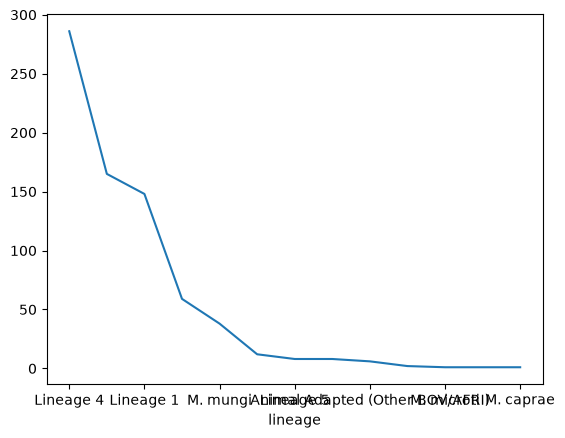

In [446]:
final=both.merge(lindf,left_on='AssemblyAccession',right_on='Isolate',how='left')
final['species'] = mtb_asm['Organism'].str.extract(r'variant\s+(\w+)', expand=False)

keepcols = ["AssemblyAccession", "AssemblyStatus", "bs_geo_loc_name", "lineage", "sublineage", "coll2014", "freschi2020","stucki2016","species","strain",
            "bs_biosample_title", "SubmitterOrganization", "SubmissionDate"]
            
final[keepcols].sort_values('sublineage').to_csv('asm_all_mtbc.csv',index=False)

<Axes: ylabel='lineage'>

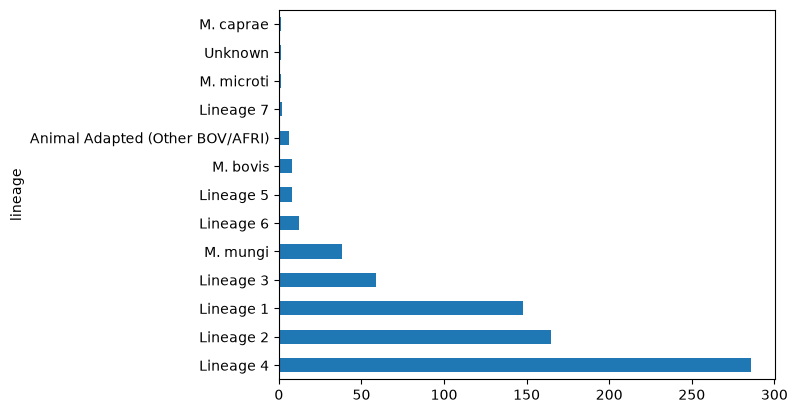

In [448]:
final.lineage.value_counts().plot(kind='barh')

In [444]:
final[["AssemblyAccession", "bs_geo_loc_name", "coll2014", "freschi2020","stucki2016","lipworth2019","species","strain","lineage"]].sample(30)

,AssemblyAccession,bs_geo_loc_name,coll2014,freschi2020,stucki2016,lipworth2019,species,strain,lineage
531,GCF_002448075.1,Peru: Lima,lineage4.3.4,4.2.1.2.1.1.i3.2,4.3/LAM,lam,NaN,TBDM2444,Lineage 4
45,GCF_061380915.1,India,NaN,NaN,NaN,NaN,NaN,NaN,NaN
477,GCF_014884665.1,India,lineage2.2.1.1,2.2.1.1.1,NaN,beijing,NaN,1-0066P6C4,Lineage 2
201,GCF_963993145.1,Nepal,lineage4.4.1.2,4.2.1.2.2.1.2,4,stype,NaN,NaN,Lineage 4
702,GCF_040734995.1,Thailand,lineage2.2.1,2.2.1.1.1,NaN,beijing,NaN,NaN,Lineage 2
354,GCF_022870265.1,Ghana,lineage5,5,NaN,"westafrican1,mungi",NaN,N1176,Lineage 5
440,GCF_014899925.1,South Africa,lineage4.1.1.3,4.1.i1.2.1,4,xtype,NaN,4-0012P6C4,Lineage 4
137,GCF_047782955.1,India: Mumbai,lineage2.2.1,2.2.1.1.1,NaN,beijing,NaN,NaN,Lineage 2
189,GCF_039555375.1,Denmark,lineageBOV_AFRI,NaN,NaN,"pinipedii,mungi",NaN,NaN,M. mungi
574,GCF_002447215.1,Peru: Lima,lineage4.3.3,4.2.1.2.1.1.i4.1,4.3/LAM,lam,NaN,TBV5362,Lineage 4


In [ ]:
print (final.groupby(['bs_geo_loc_name','coll2014']).size())

## download assemblies

In [199]:
def add_genomic_fasta_urls(
    df: pd.DataFrame, ftp_col: str = "FtpPath_GenBank", new_col: str = "genomic_fna_url"
) -> pd.DataFrame:
    """Add a column with the direct genomic FASTA (.fna.gz) URL for every row."""
    df = df.copy()
    df[new_col] = df[ftp_col].apply(ftp_dir_to_genomic_fna_url)
    return df
 
def ftp_dir_to_genomic_fna_url(ftp_dir_url: str) -> str:
    """
    Construct the direct genomic FASTA URL from an NCBI assembly FTP/HTTPS
    directory URL, e.g.:
 
        .../GCA_000270345.1_ASM27034v1
        -> .../GCA_000270345.1_ASM27034v1/GCA_000270345.1_ASM27034v1_genomic.fna.gz
 
    NCBI always names the trailing directory "{accession}_{assembly_name}",
    and every file inside reuses that exact string as a prefix -- so this is
    pure string construction, no extra lookup needed. Same pattern works for
    other suffixes too, e.g. "_assembly_report.txt", "_genomic.gff.gz",
    "_protein.faa.gz", "_cds_from_genomic.fna.gz".
    """
    if not isinstance(ftp_dir_url, str) or not ftp_dir_url:
        return ""
    ftp_dir_url = ftp_dir_url.rstrip("/")
    basename = posixpath.basename(ftp_dir_url)
    return f"{ftp_dir_url}/{basename}_genomic.fna.gz"
     
def download_assembly_fastas(df: pd.DataFrame, out_dir: str, ftp_col: str = "FtpPath_GenBank",
        accession_col: str = "AssemblyAccession", gunzip: bool = True):
    """
    Download the genomic FASTA for every assembly in `df` into `out_dir`,
    named "{AssemblyAccession}.fna" (or ".fna.gz" if gunzip=False).
 
    Adds/overwrites a "local_fasta_path" column with the downloaded path
    (or None if the download failed), so failures are visible rather than
    silently missing files later in the pipeline.
    """
    os.makedirs(out_dir, exist_ok=True)
    df = df.copy()
    local_paths = []
 
    for _, row in df.iterrows():
        url = ftp_dir_to_genomic_fna_url(row.get(ftp_col, ""))
        accession = row.get(accession_col, "unknown")
        fna_path = os.path.join(out_dir, f"{accession}.fna")
        if os.path.exists(fna_path):
            print (f'file {fna_path} present, skipping..')
            continue
        if not url:
            print(f"  [skip] {accession}: no {ftp_col} value")
            local_paths.append(None)
            continue
 
        gz_path = os.path.join(out_dir, f"{accession}.fna.gz")
        try:
            print(f"  Downloading {accession} ...")
            urllib.request.urlretrieve(url, gz_path)
        except Exception as e:
            print(f"  [FAILED] {accession}: {e}")
            continue
 
        if gunzip:
            try:
                with gzip.open(gz_path, "rb") as f_in, open(fna_path, "wb") as f_out:
                    shutil.copyfileobj(f_in, f_out)
                os.remove(gz_path)
            except:
                pass
    return


In [ ]:
df = add_genomic_fasta_urls(mtb_asm)
download_assembly_fastas(df, out_dir="mtb_genomes")

In [ ]:
df = add_genomic_fasta_urls(lr)
download_assembly_fastas(df, out_dir="mtb_genomes_lr")

## remove redundant genomes

In [8]:
def run_mash(assemblies: List[str], work_dir: str, threads: int = 4) -> str:
    """Sketch all assemblies and compute the all-vs-all distance matrix. Returns path to the distances TSV."""
    sketch_prefix = os.path.join(work_dir, "sketches")
    subprocess.run(
        ["mash", "sketch", "-p", str(threads), "-o", sketch_prefix] + assemblies,
        check=True, capture_output=True, text=True,
    )
    sketch_file = sketch_prefix + ".msh"
 
    dist_path = os.path.join(work_dir, "distances.tsv")
    with open(dist_path, "w") as out_fh:
        subprocess.run(
            ["mash", "dist", "-p", str(threads), sketch_file, sketch_file],
            check=True, stdout=out_fh,
        )
    return dist_path
 
 
def cluster_by_distance(dist_path: str, threshold: float) -> Dict[str, int]:
    """Build a graph (edge if distance < threshold) and return {assembly_path: cluster_id}."""
    edges = []
    nodes = set()
    with open(dist_path) as fh:
        for line in fh:
            a, b, dist_str, *_ = line.strip().split("\t")
            nodes.update([a, b])
            if a != b and float(dist_str) < threshold:
                edges.append((a, b))
 
    G = nx.Graph()
    G.add_nodes_from(nodes)
    G.add_edges_from(edges)
 
    cluster_of = {}
    for cluster_id, component in enumerate(nx.connected_components(G)):
        for node in component:
            cluster_of[node] = cluster_id
    return cluster_of
 
 
def pick_representatives(cluster_of: Dict[str, int]) -> pd.DataFrame:
    """For each cluster, pick the assembly with the largest total sequence length as representative."""
    rows = []
    for path, cid in cluster_of.items():
        total_len = sum(len(rec.seq) for rec in SeqIO.parse(path, "fasta"))
        rows.append({"assembly_file": path, "cluster_id": cid, "total_length": total_len})
 
    df = pd.DataFrame(rows)
    df["is_representative"] = False
    rep_idx = df.groupby("cluster_id")["total_length"].idxmax()
    df.loc[rep_idx, "is_representative"] = True
    return df.sort_values(["cluster_id", "is_representative"], ascending=[True, False])
 

In [ ]:
dist_path = run_mash(assemblies, args.out_dir, threads=args.threads)

cluster_of = cluster_by_distance(dist_path, args.threshold)
df = pick_representatives(cluster_of)

summary_path = os.path.join(args.out_dir, "dereplication_summary.csv")

## search for up to date WGS data for animal adapted species only

In [ ]:
query = (
    '("Mycobacterium africanum" OR "Mycobacterium caprae" OR '# "Mycobacterium bovis" OR '
    '"Mycobacterium pinnipedii" OR "Mycobacterium microti" OR '
    '"Mycobacterium mungi" OR "Mycobacterium orygis" OR "Mycobacterium surricatae")'
    #'AND ("2019/01/01"[PDAT] : "2026/12/31"[PDAT])'
)

handle = Entrez.esearch(db="sra", term=query, usehistory="y", retmax=2000)
res = Entrez.read(handle)
handle.close()

count = int(res["Count"])
webenv, query_key = res["WebEnv"], res["QueryKey"]
print(f"{count} hits")

In [8]:
rows = []
header = None
batch = 500
for start in range(0, count, batch):
    with Entrez.efetch(db="sra", rettype="runinfo", retmode="text",
                       retstart=start, retmax=batch,
                       webenv=webenv, query_key=query_key) as h:
        data = h.read()
    if isinstance(data, bytes):
        data = data.decode("utf-8", errors="replace")
    reader = csv.reader(io.StringIO(data))
    for i, row in enumerate(reader):
        if not row or row[0] == "Run": 
            if header is None and row:
                header = row
            continue
        rows.append(row)

import pandas as pd
sra = pd.DataFrame(rows, columns=header)
sra.to_csv("sra_mtbc_animal.csv", index=False)

In [17]:
# 1. Confirm the taxid resolves and check linked record counts directly
handle = Entrez.esearch(db="taxonomy", term="Mycobacterium ")
tax_id = Entrez.read(handle)["IdList"]
print(tax_id)

# 2. Search SRA using the taxid directly via [Organism] rather than free text
# this bypasses any string-matching mismatch in ScientificName field
handle = Entrez.esearch(db="sra", term="txid1844474[Organism:exp]")
print(Entrez.read(handle)["Count"])

['1844474']
1


In [5]:
sra = pd.read_csv("sra_mtbc_animal.csv")

In [6]:
sra["ReleaseDate"] = pd.to_datetime(sra["ReleaseDate"], errors="coerce")
sra["year"] = sra["ReleaseDate"].dt.year
print(sra["year"].value_counts().sort_index())

year
2011     13
2013     91
2014     99
2015    142
2016    129
2017     28
2018     29
2019    161
2020    680
2021    127
2022     34
2023    376
2024    111
2025    249
2026    168
Name: count, dtype: int64


In [11]:
sub = sra[sra.year>=2019]
sub.ScientificName.value_counts()
#sub.size_MB.astype(int).hist()

ScientificName
Mycobacterium tuberculosis variant africanum             874
Mycobacterium tuberculosis variant caprae                250
Mycobacterium tuberculosis                               246
Mycobacterium orygis                                     232
Mycobacterium tuberculosis variant bovis                 134
whole organism metagenome                                 96
Mycobacterium tuberculosis variant africanum GM041182     53
Mycobacterium tuberculosis variant microti                11
Bos taurus                                                 6
Mycobacterium tuberculosis variant pinnipedii              4
Name: count, dtype: int64

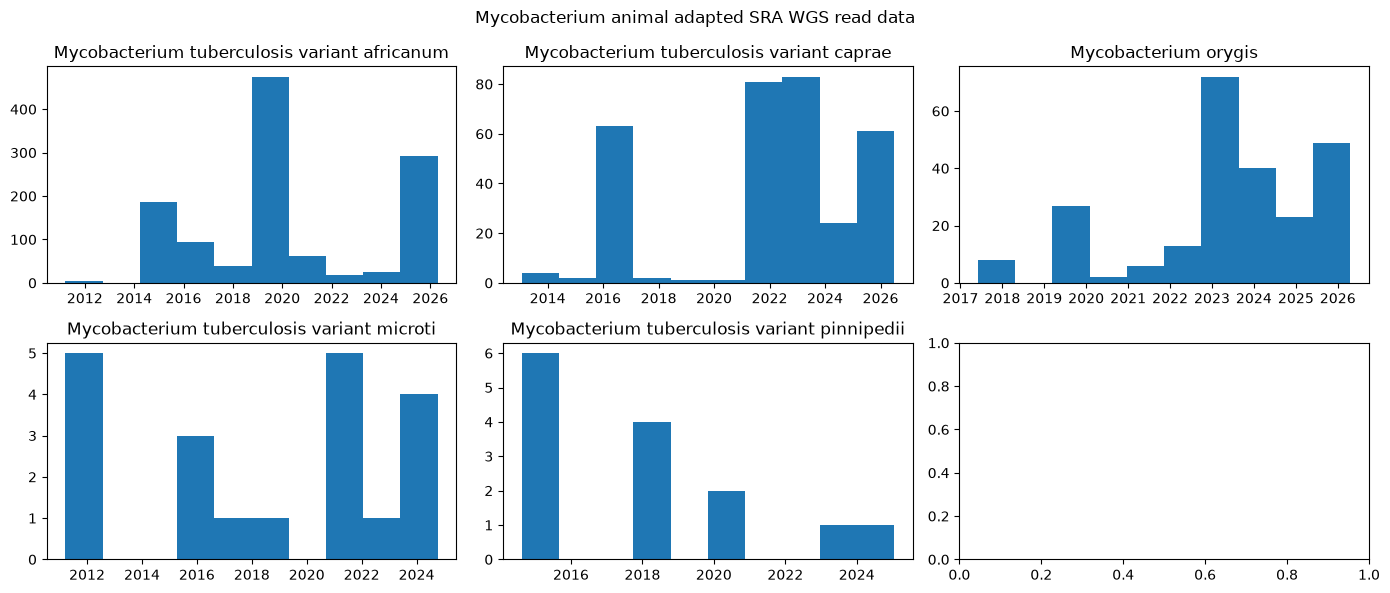

In [17]:
fig,axs=plt.subplots(2,3,figsize=(14,6))
i=0
axs=axs.flat
for s in species:
    x=sra[sra.ScientificName==s]
    if len(x)==0: continue
    dates=pd.to_datetime(x.ReleaseDate)
    dates.hist(ax=axs[i],grid=False)
    axs[i].set_title(s)
    i+=1

fig.suptitle('Mycobacterium animal adapted SRA WGS read data')
plt.tight_layout()

In [76]:
sra[sra.ScientificName.isnull()]
sra.columns
scols = ['Run','ScientificName','ReleaseDate','avgLength', 'size_MB', 'AssemblyName','CenterName', 'BioProject','Platform','SampleType']

sra.sample(5)

Index(['Run', 'ReleaseDate', 'LoadDate', 'spots', 'bases', 'spots_with_mates', 'avgLength', 'size_MB', 'AssemblyName', 'download_path', 'Experiment', 'LibraryName', 'LibraryStrategy',
       'LibrarySelection', 'LibrarySource', 'LibraryLayout', 'InsertSize', 'InsertDev', 'Platform', 'Model', 'SRAStudy', 'BioProject', 'Study_Pubmed_id', 'ProjectID', 'Sample', 'BioSample',
       'SampleType', 'TaxID', 'ScientificName', 'SampleName', 'g1k_pop_code', 'source', 'g1k_analysis_group', 'Subject_ID', 'Sex', 'Disease', 'Tumor', 'Affection_Status', 'Analyte_Type',
       'Histological_Type', 'Body_Site', 'CenterName', 'Submission', 'dbgap_study_accession', 'Consent', 'RunHash', 'ReadHash', 'year'],
      dtype='str')

In [108]:
def apply_size_filter(df, min_mb=80, max_mb=500):
    """Size filter, skipped for long-read platforms."""
    
    long_read = df["Platform"].isin(["OXFORD_NANOPORE", "PACBIO_SMRT"])
    in_range = df["size_MB"].between(min_mb, max_mb)
    return df[long_read | in_range].reset_index(drop=True)

def stratify_sra_table(df, stratify_cols=["ScientificName", "BioProject"], n=10, exclude_taxa=None):
  """Stratifies an SRA DataFrame, filtering out unwanted taxa and

  sampling up to n rows per stratum (retaining all rows for strata
  smaller than n).

  Parameters:
  - df: pandas DataFrame containing the SRA metadata.
  - stratify_cols: List of columns to group/stratify by.
  - n: Maximum number of samples to draw per stratum.
  - exclude_taxa: List or set of scientific names to filter out.

  Returns:
  - Stratified pandas DataFrame.
  """
  df_filtered = df.copy()

  # 1. Filter out non-specific species/categories if specified
  if exclude_taxa and "ScientificName" in df_filtered.columns:
    df_filtered = df_filtered[
        ~df["ScientificName"].isin(exclude_taxa)
    ]
  pattern = r"^*MAL"
  df_filtered = df_filtered[~df_filtered["ScientificName"].str.contains(pattern, regex=True, na=False)]

  #  Stratified sampling with safe handling for small strata (< n)
  def sample_stratum(group):
    sample_size = min(len(group), n)
    return group.sample(n=sample_size, random_state=42)
  stratified_df = (
      df_filtered.groupby(stratify_cols)
      .apply(sample_stratum)
      .reset_index(drop=False)
  )
  return stratified_df

exclude_list = ['whole organism metagenome','Mycobacterium tuberculosis variant africanum GM041182',
                'Mycobacterium tuberculosis','Bos taurus','unidentified']
strat = stratify_sra_table(
     sra,
     stratify_cols=["ScientificName", "BioProject"],
     n=3,
     exclude_taxa=exclude_list)
print (len(strat))
strat[scols].to_csv('sra_mtbc_animal_reduced.csv')

223


In [112]:
strat.ScientificName.value_counts()

ScientificName
Mycobacterium tuberculosis variant africanum     82
Mycobacterium orygis                             55
Mycobacterium tuberculosis variant caprae        49
Mycobacterium tuberculosis variant microti       17
Mycobacterium tuberculosis variant pinnipedii    11
Mycobacterium tuberculosis variant bovis          6
Mycobacterium marinum                             2
Mycobacterium mungi                               1
Name: count, dtype: int64

In [113]:
strat.Platform.value_counts()

Platform
ILLUMINA           208
PACBIO_SMRT         10
OXFORD_NANOPORE      4
ION_TORRENT          1
Name: count, dtype: int64

<Axes: >

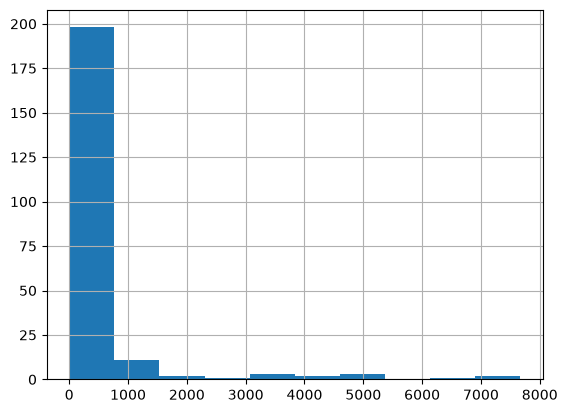

In [134]:
strat.size_MB.hist()

In [ ]:
## download the files
def download_sra_fastqs(df, run_col="Run", outdir="read_data", check_size=True, threads=4):
  """Downloads FASTQ files using fasterq-dump for high performance,

  handles paired-end reads automatically, and compresses them with gzip.

  Parameters:
  - df: pandas DataFrame containing your SRA metadata.
  - run_col: Column name containing the Run accessions.
  - outdir: Directory where files will be saved.
  - threads: Number of CPU threads for fasterq-dump to use.
  """
    
  os.makedirs(outdir, exist_ok=True)
  #for run_id in df[run_col].dropna().unique():
  for i,row in df.iterrows():    
    run_id = row.Run
    print(f"\nProcessing: {run_id}")
    if check_size==True:
        size = row.size_MB
        if (size > 500) or (size < 25):
            print ('size too large or small')
            continue
    f = os.path.join(outdir, f"{run_id}_1.fastq.gz")
    if os.path.exists(f):
        continue
    exclude = ['SRR30133597','SRR30133598','SRR24255213','SRR30133601','SRR12395420','SRR12395420','SRR30133602','SRR12395164']
    if run_id in exclude:
        continue
    # 1. Download using fasterq-dump (splits paired-end reads by default)
    cmd_download = [
        "fasterq-dump",
        str(run_id),
        "--outdir",
        outdir,
        "--threads",
        str(threads),
        "-p",  # Show progress bar
    ]

    try:
      subprocess.run(cmd_download, check=True)
      print(f"Downloaded {run_id}, now compressing...")

      # Compress any generated fastq files for this specific run ID
      fastq_files = glob.glob(os.path.join(outdir, f"{run_id}*.fastq"))

      for fq_file in fastq_files:
        print(f"Compressing: {os.path.basename(fq_file)}")
        subprocess.run(["gzip", "-f", fq_file], check=True)

      print(f"Successfully finished: {run_id}")

    except subprocess.CalledProcessError as e:
      print(f"Error processing {run_id}: {e}")

In [141]:
strat[scols]

,Run,ScientificName,ReleaseDate,avgLength,size_MB,AssemblyName,CenterName,BioProject,Platform,SampleType
0,ERR027299,Mycobacterium marinum,2011-03-18 11:38:02,224,165,NaN,SC,PRJEB2091,ILLUMINA,simple
1,ERR027300,Mycobacterium marinum,2011-03-18 11:38:02,224,222,NaN,SC,PRJEB2091,ILLUMINA,simple
2,SRR3500411,Mycobacterium mungi,2016-05-17 16:47:58,458,354,NaN,NATIONAL VETERINARY SERVICES LABORATORIES,PRJNA320514,ILLUMINA,simple
3,ERR5336161,Mycobacterium orygis,2021-03-16 23:07:15,286,343,NaN,NORWEGIAN INSTITUTE OF PUBLIC HEALTH,PRJEB43202,ILLUMINA,simple
4,ERR5336162,Mycobacterium orygis,2021-03-16 23:07:15,493,214,NaN,NORWEGIAN INSTITUTE OF PUBLIC HEALTH,PRJEB43202,ILLUMINA,simple
...,...,...,...,...,...,...,...,...,...,...
218,SRR1239339,Mycobacterium tuberculosis variant pinnipedii,2014-08-15 00:00:00,602,286,NaN,UNIVERSITY OF TUEBINGEN,PRJNA244633,ILLUMINA,simple
219,SRR7693584,Mycobacterium tuberculosis variant pinnipedii,2018-08-14 17:56:16,199,388,NaN,UNIVERSITY OF SAO P AULO,PRJNA439165,ILLUMINA,simple
220,SRR6866950,Mycobacterium tuberculosis variant pinnipedii,2018-03-20 02:25:33,95,379,NaN,UNIVERSIDADE DE SAO PAULO,PRJNA439165,ILLUMINA,simple
221,SRR6875521,Mycobacterium tuberculosis variant pinnipedii,2018-03-21 16:04:45,96,368,NaN,UNIVERSIDADE DE SAO PAULO,PRJNA442753,ILLUMINA,simple


<Axes: >

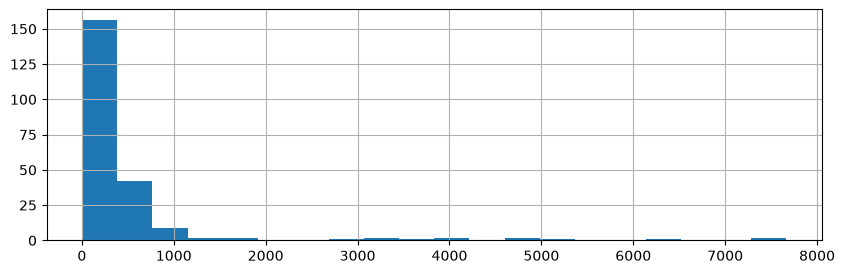

In [118]:
strat.size_MB.astype(int).hist(bins=20,figsize=(10,3))

In [ ]:
#download_sra_fastqs(strat, outdir="alex_data", check_size=False, threads=12)

## elena reads data <2019

In [147]:
elena = pd.read_csv('../genomes_data.csv')

In [ ]:
download_sra_fastqs(elena, outdir="elena_data", check_size=False, threads=12)

## old

In [109]:
def run_mash(assemblies: List[str], work_dir: str, threads: int = 4):
    """Sketch all assemblies and compute the all-vs-all distance matrix. Returns path to the distances TSV."""
    
    sketch_prefix = os.path.join(work_dir, "sketches")
    subprocess.run(
        ["mash", "sketch", "-p", str(threads), "-o", sketch_prefix] + assemblies,
        check=True, capture_output=True, text=True,
    )
    sketch_file = sketch_prefix + ".msh"
 
    dist_path = os.path.join(work_dir, "distances.tsv")
    with open(dist_path, "w") as out_fh:
        subprocess.run(
            ["mash", "dist", "-p", str(threads), sketch_file, sketch_file],
            check=True, stdout=out_fh,
        )
    return dist_path
 
def cluster_by_distance(dist_path: str, threshold: float) -> Dict[str, int]:
    """Build a graph (edge if distance < threshold) and return {assembly_path: cluster_id}."""
    edges = []
    nodes = set()
    with open(dist_path) as fh:
        for line in fh:
            a, b, dist_str, *_ = line.strip().split("\t")
            nodes.update([a, b])
            if a != b and float(dist_str) < threshold:
                edges.append((a, b))
 
    G = nx.Graph()
    G.add_nodes_from(nodes)
    G.add_edges_from(edges)
 
    cluster_of = {}
    for cluster_id, component in enumerate(nx.connected_components(G)):
        for node in component:
            cluster_of[node] = cluster_id
    return cluster_of
 
def pick_representatives(cluster_of: Dict[str, int]) -> pd.DataFrame:
    """For each cluster, pick the assembly with the largest total sequence length as representative."""
    rows = []
    for path, cid in cluster_of.items():
        total_len = sum(len(rec.seq) for rec in SeqIO.parse(path, "fasta"))
        rows.append({"assembly_file": path, "cluster_id": cid, "total_length": total_len})
 
    df = pd.DataFrame(rows)
    df["is_representative"] = False
    rep_idx = df.groupby("cluster_id")["total_length"].idxmax()
    df.loc[rep_idx, "is_representative"] = True
    return df.sort_values(["cluster_id", "is_representative"], ascending=[True, False])


In [201]:
files = glob.glob('mtb_genomes/*.fna')
dist_path = run_mash(files, 'temp', threads=12)
threshold=.0005
cluster_of = cluster_by_distance(dist_path,threshold)
df = pick_representatives(cluster_of)
df.to_csv("dereplication_summary.csv", index=False)

n_clusters = df["cluster_id"].nunique()
print(f"\n{len(files)} assemblies -> {n_clusters} clusters at threshold={threshold}")


684 assemblies -> 59 clusters at threshold=0.0005
